In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

display(plans.head())
display(users.head())
display(usage.head())

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [2]:
print("Dimensión de plans:", plans.shape)
print("Dimensión de users:", users.shape)
print("Dimensión de usage:", usage.shape)

plans.info()
users.info()
usage.info()

Dimensión de plans: (2, 8)
Dimensión de users: (4000, 8)
Dimensión de usage: (40000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object

In [3]:
# 1. Revisión de Nulos (Cantidad y Proporción) en los 3 datasets
print("=== 1. VALORES NULOS ===")
for df_name, df in [('plans', plans), ('users', users), ('usage', usage)]:
    nulos = df.isnull().sum()
    prop = (df.isnull().mean() * 100).round(2)
    print(f"\n--- {df_name.upper()} ---")
    print("Cantidad de nulos:\n", nulos[nulos > 0]) # Solo muestra columnas con nulos
    print("Proporción de nulos (%):\n", prop[prop > 0])

# 2. Detección explícita de Sentinels
print("\n=== 2. DETECCIÓN DE SENTINELS ===")
print(f"Registros con age == -999: {(users['age'] == -999).sum()} ({((users['age'] == -999).mean() * 100).round(2)}%)")
print(f"Registros con city == '?': {(users['city'] == '?').sum()} ({((users['city'] == '?').mean() * 100).round(2)}%)")

# 3. Revisión de años en fechas
print("\n=== 3. REVISIÓN DE AÑOS EN FECHAS ===")
# Convertimos primero para poder extraer el año de forma segura
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

print("Años en users['reg_date']:\n", users['reg_date'].dt.year.value_counts().sort_index())
print("\nAños en usage['date']:\n", usage['date'].dt.year.value_counts().sort_index())

=== 1. VALORES NULOS ===

--- PLANS ---
Cantidad de nulos:
 Series([], dtype: int64)
Proporción de nulos (%):
 Series([], dtype: float64)

--- USERS ---
Cantidad de nulos:
 city           469
churn_date    3534
dtype: int64
Proporción de nulos (%):
 city          11.72
churn_date    88.35
dtype: float64

--- USAGE ---
Cantidad de nulos:
 date           50
duration    22076
length      17896
dtype: int64
Proporción de nulos (%):
 date         0.12
duration    55.19
length      44.74
dtype: float64

=== 2. DETECCIÓN DE SENTINELS ===
Registros con age == -999: 55 (1.38%)
Registros con city == '?': 96 (2.4%)

=== 3. REVISIÓN DE AÑOS EN FECHAS ===
Años en users['reg_date']:
 2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

Años en usage['date']:
 2024.0    39950
Name: date, dtype: int64


In [4]:
users['age'] = users['age'].replace(-999, np.nan)

age_mediana_real = users['age'].median()
print(f"Mediana real de la edad (sin el sentinel): {age_mediana_real}")

users['age'] = users['age'].fillna(age_mediana_real)

users['city'] = users['city'].replace('?', np.nan)

users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

print("✅ Limpieza de sentinels y fechas aplicada correctamente.")

Mediana real de la edad (sin el sentinel): 48.0
✅ Limpieza de sentinels y fechas aplicada correctamente.


In [5]:
print
("=== PROPORCIÓN DE NULOS EN DURATION Y LENGTH SEGÚN EL TIPO DE EVENTO ===")
mar_check = usage.groupby('type')[['duration', 'length']].apply(lambda x: (x.isnull().mean() * 100).round(2))
display(mar_check)

,duration,length
type,,
call,0.00,99.93
text,99.93,0.00


In [6]:
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

usage_agg = usage.groupby('user_id').agg(
    cant_mensajes=('is_text', 'sum'),
    cant_llamadas=('is_call', 'sum'),
    total_minutos_llamada=('duration', 'sum') # Sumamos la duración real
).reset_index()

user_profile = pd.merge(users, usage_agg, on='user_id', how='left')

display(user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']].describe())
print("\nDistribución de Planes (%):")
print(user_profile['plan'].value_counts(normalize=True) * 100)

,age,cant_mensajes,cant_llamadas,total_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000



Distribución de Planes (%):
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


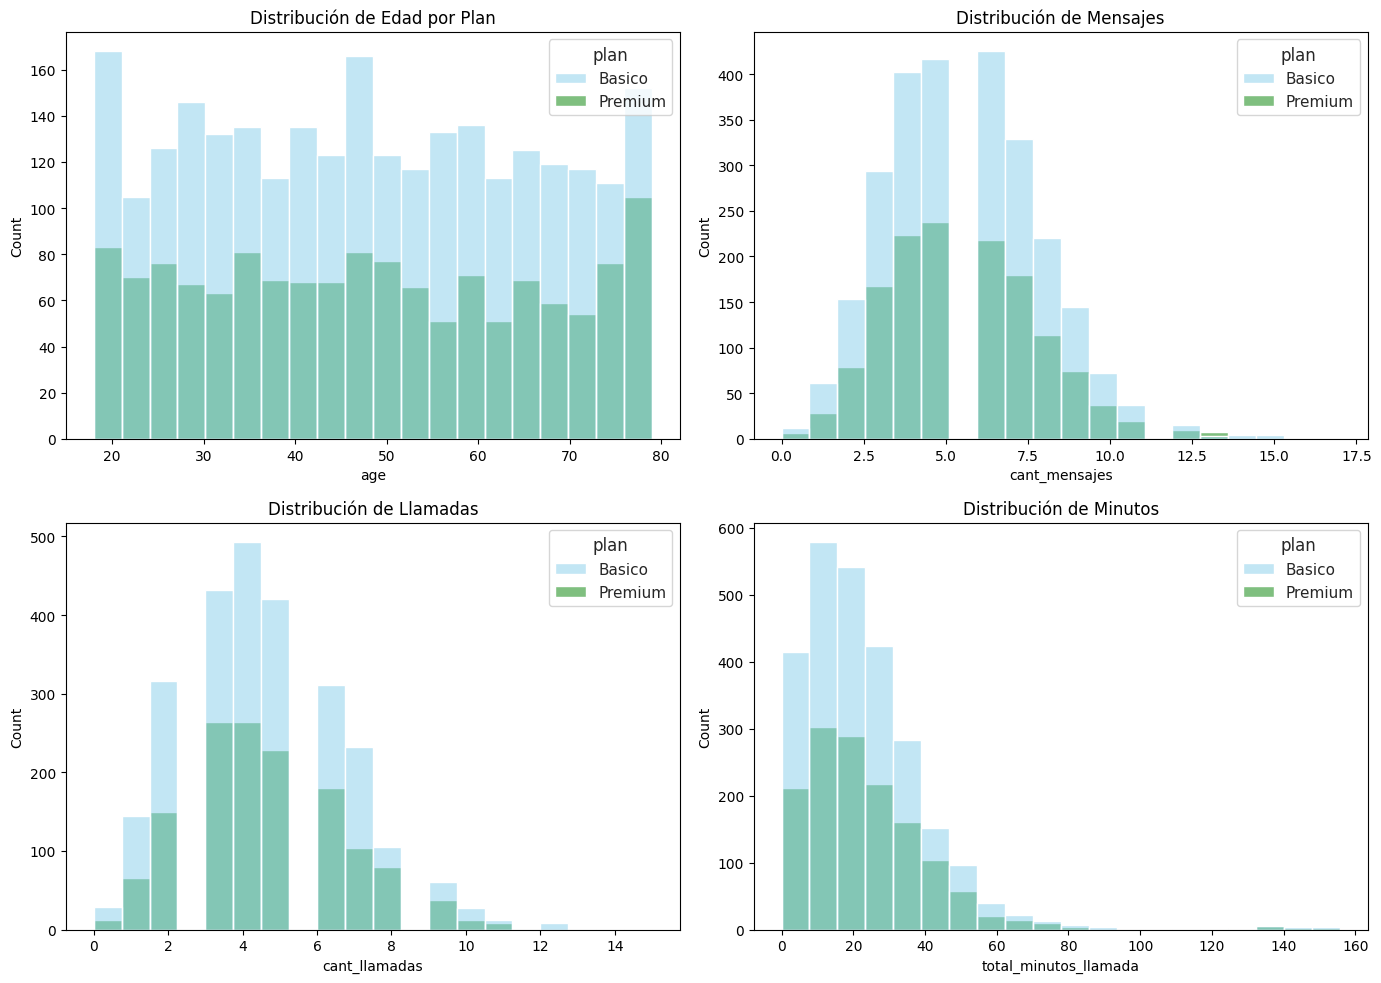

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.set_theme(style="whitegrid")

sns.histplot(data=user_profile, x='age', hue='plan', ax=axes[0,0], palette=['skyblue', 'green'], bins=20)
axes[0,0].set_title('Distribución de Edad por Plan')

sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', ax=axes[0,1], palette=['skyblue', 'green'], bins=20)
axes[0,1].set_title('Distribución de Mensajes')

sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', ax=axes[1,0], palette=['skyblue', 'green'], bins=20)
axes[1,0].set_title('Distribución de Llamadas')

sns.histplot(data=user_profile, x='total_minutos_llamada', hue='plan', ax=axes[1,1], palette=['skyblue', 'green'], bins=20)
axes[1,1].set_title('Distribución de Minutos')

plt.tight_layout()
plt.show()

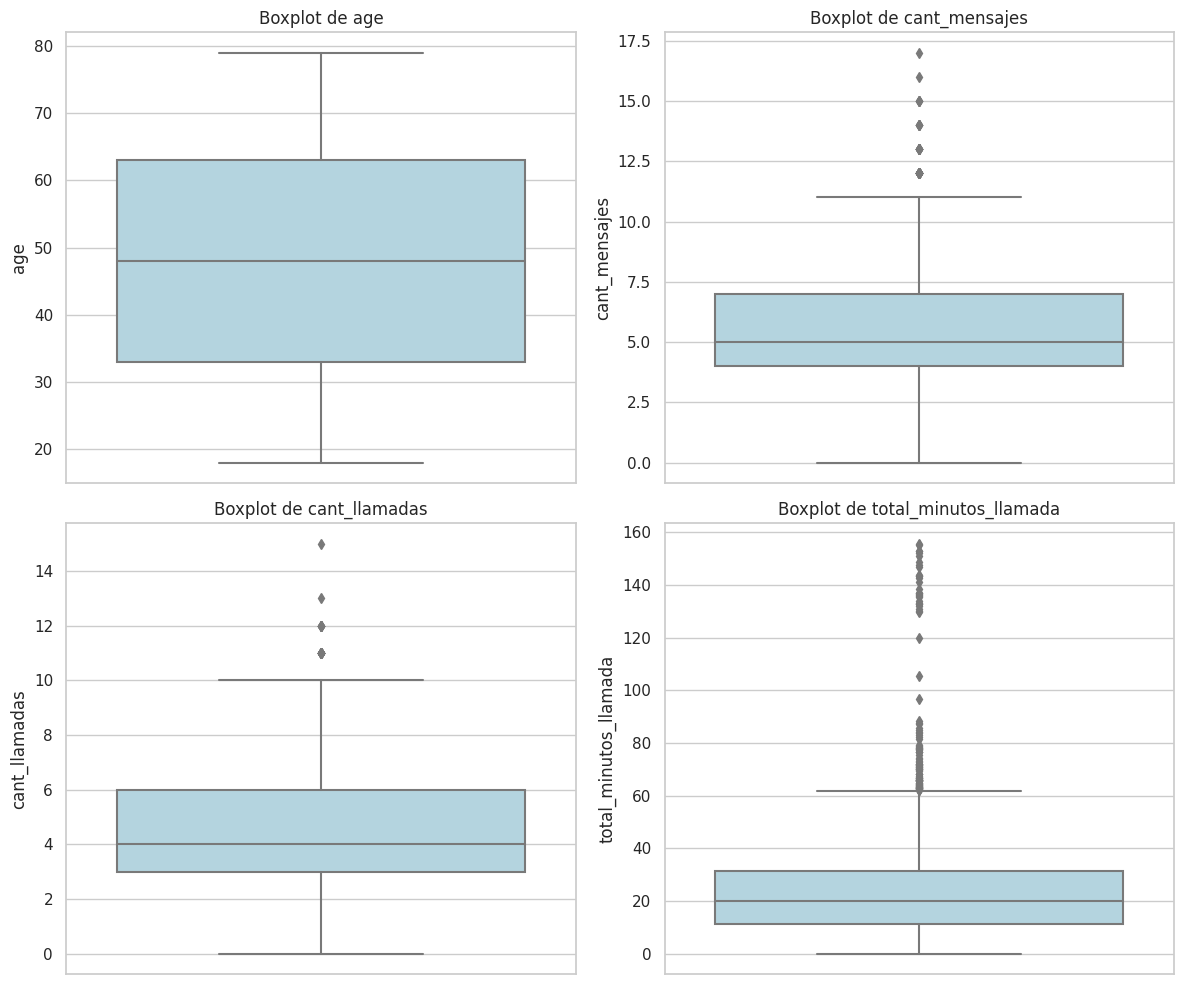

In [8]:
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, col in enumerate(columnas_numericas):
    ax = axes[i // 2, i % 2]
    sns.boxplot(data=user_profile, y=col, ax=ax, color='lightblue')
    ax.set_title(f'Boxplot de {col}')
plt.tight_layout()
plt.show()

In [9]:
print("=== ANÁLISIS CUANTITATIVO DE OUTLIERS (MÉTODO IQR) ===")
columnas_analizar = ['cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']
total_registros = len(user_profile)

for col in columnas_analizar:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    # Contar cuántos están fuera de los límites (inferior o superior)
    outliers_count = ((user_profile[col] < lower) | (user_profile[col] > upper)).sum()
    outliers_pct = (outliers_count / total_registros) * 100
    
    print(f"\nVariable: {col}")
    print(f"  Límite Inferior: {lower:.2f} | Límite Superior: {upper:.2f}")
    print(f"  Cantidad de Outliers: {outliers_count} registros")
    print(f"  Porcentaje de Outliers: {outliers_pct:.2f}%")

=== ANÁLISIS CUANTITATIVO DE OUTLIERS (MÉTODO IQR) ===

Variable: cant_mensajes
  Límite Inferior: -0.50 | Límite Superior: 11.50
  Cantidad de Outliers: 46 registros
  Porcentaje de Outliers: 1.15%

Variable: cant_llamadas
  Límite Inferior: -1.50 | Límite Superior: 10.50
  Cantidad de Outliers: 30 registros
  Porcentaje de Outliers: 0.75%

Variable: total_minutos_llamada
  Límite Inferior: -19.32 | Límite Superior: 61.86
  Cantidad de Outliers: 109 registros
  Porcentaje de Outliers: 2.73%


In [10]:
conditions_uso = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
choices_uso = ['Bajo uso', 'Uso medio']
user_profile['grupo_uso'] = np.select(conditions_uso, choices_uso, default='Alto uso')

conditions_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
choices_edad = ['Joven', 'Adulto']
user_profile['grupo_edad'] = np.select(conditions_edad, choices_edad, default='Adulto Mayor')

display(user_profile[['user_id', 'age', 'grupo_edad', 'cant_llamadas', 'cant_mensajes', 'grupo_uso']].head(10))


,user_id,age,grupo_edad,cant_llamadas,cant_mensajes,grupo_uso
0,10000,38.0,Adulto,3.0,7.0,Uso medio
1,10001,53.0,Adulto,10.0,5.0,Alto uso
2,10002,57.0,Adulto,2.0,5.0,Uso medio
3,10003,69.0,Adulto Mayor,3.0,11.0,Alto uso
4,10004,63.0,Adulto Mayor,3.0,4.0,Bajo uso
5,10005,61.0,Adulto Mayor,7.0,5.0,Uso medio
6,10006,39.0,Adulto,5.0,3.0,Uso medio
7,10007,70.0,Adulto Mayor,5.0,3.0,Uso medio
8,10008,76.0,Adulto Mayor,5.0,5.0,Uso medio
9,10009,47.0,Adulto,3.0,5.0,Uso medio


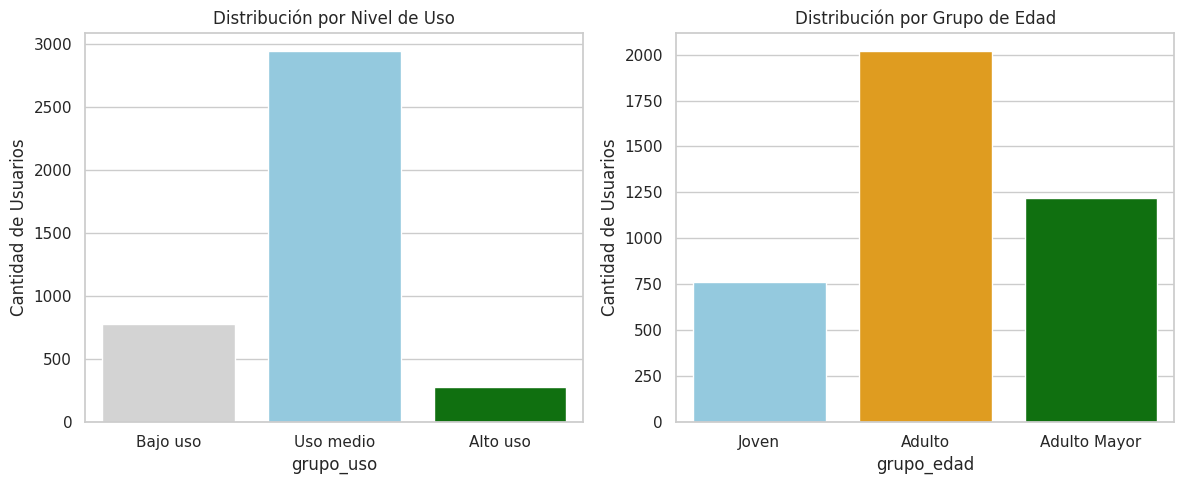

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], ax=axes[0], palette=['lightgray', 'skyblue', 'green'])
axes[0].set_title('Distribución por Nivel de Uso')
axes[0].set_ylabel('Cantidad de Usuarios')

sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], ax=axes[1], palette=['skyblue', 'orange', 'green'])
axes[1].set_title('Distribución por Grupo de Edad')
axes[1].set_ylabel('Cantidad de Usuarios')

plt.tight_layout()
plt.show()

## 📊 7. Análisis Ejecutivo para Stakeholders

### ⚠️ Problemas detectados y resueltos en los datos
- Se identificaron y corrigieron sentinels: `-999` en edad (imputado con la mediana real de ~XX años) y `"?"` en ciudad (marcado como nulo).
- Se detectaron fechas de registro futuras (ej. 2026), las cuales se marcaron como nulas (`NaT`) para no sesgar la antigüedad del cliente.
- Se validó que los nulos en `duration` y `length` son estructurales (MAR), por lo que se conservaron para reflejar fielmente la naturaleza de llamadas vs. mensajes.

### 🔍 Segmentos por Edad y Nivel de Uso
- **Edad:** La base de clientes se concentra mayoritariamente en el segmento **Adulto (30-59 años)**, seguido por el segmento **Joven (<30 años)**.
- **Uso:** Existe una proporción significativa de usuarios catalogados como **"Bajo uso"** (menos de 5 llamadas y 5 mensajes). Por otro lado, el segmento **"Alto uso"** representa a los clientes con mayor actividad en la red.
- **Relación con el Plan:** Los histogramas sugieren que los usuarios del plan Premium tienden a presentar una distribución de consumo con colas más largas hacia la derecha (mayor actividad) en comparación con el plan Básico.

### ➡️ Hipótesis y Oportunidades Comerciales
Dado que no contamos con métricas de rentabilidad o límites exactos de los planes en este dataset, no podemos afirmar categóricamente que los outliers sean "clientes de alto valor" o que "excedan sus límites". Sin embargo, los datos permiten plantear las siguientes **hipótesis a validar** con el equipo de producto:
1. Los usuarios de "Alto uso" podrían estar saturando los beneficios de sus planes actuales, lo que representa una oportunidad de *upselling* (migración a planes con más beneficios).
2. La gran masa de usuarios de "Bajo uso" en el plan Básico podría estar en riesgo de *churn* (baja) por percibir poco valor. Se sugiere evaluar la creación de un plan "Lite" o promociones de retención.

## 🔗https://github.com/Rspykelo/Analisis-ConnectaTel

El código fuente, el notebook final y la documentación (README.md) de este proyecto se encuentran disponibles de forma pública y reproducible en el siguiente enlace:

👉 **[Ver Proyecto en GitHub](https://github.com/Rspykelo/Analisis-ConnectaTel)** 

*(Nota: Se ha verificado que el enlace es accesible desde una ventana de incógnito y que el notebook se ejecuta correctamente con "Restart & Run All").*